### rc_test1_silo

Using the rudimentary ESN implementation in 'juvenile_ESN_ver2' on actual data sourced from  
the SILO Dataset 
- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1  

--- Date:    March 2026

In [1]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def collect_data(form,lat,lon,start,finish,username,password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')


In [ ]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')
    
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass
    
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

In [ ]:
def smooth_data(df,window, min_periods):
    """
    smoothing data to minimise noise using rolling window average
    """
    df['Rain.Mean'] = df.Rain.rolling(window=window,min_periods=min_periods).mean()

In [ ]:
#Brunswick Junction (9513) - (Kwinana West Port Zone)
brunswick_data = collect_data('standard','-33.21','115.85','20010101','20260327','email@gmail.com')
brunswick_clean = clean_data(brunswick_data)
brunswick_clean['Rain.Mean'] = brunswick_clean.Rain.rolling(window=180,min_periods=1).mean()

#Northam (10111) - Kwinana East Port Zone
northam_data = collect_data('standard','-31.65','116.66','20010101','20260327','email@gmail.com')
northam_clean = clean_data(northam_data)
northam_clean['Rain.Mean'] = northam_clean.Rain.rolling(window=180,min_periods=1).mean()


# extracting rain and cumulative growing degree days.
brunswick_rain = brunswick_clean[['Rain.Mean']].values
brunswick_gddc = brunswick_clean[['GDD.C']].values



In [6]:
# p = spectral radius
p = 1.1
d = 5 # average connections per neuron
N = 100 # number of nodes 

# creating the weight matrix - identity matrix of 10x10
Vadj = np.multiply(
    np.random.binomial(size=(N,N), p=d/N, n=1),
    np.random.normal(size=(N,N)))
# multiply by spectral radius to control stability and memory 
Vadj = Vadj * (p/np.max(np.absolute(np.linalg.eig(Vadj)[0])))

#creating random input weights 
Vin = np.random.uniform(-1,1,size=(N,1))

#creating bias vector (Nx number of obs)
Vbias = np.random.uniform(-1,1,size=(N,))

x = np.zeros(N)
#reservoir states
states = np.zeros((len(brunswick_rain), N))

for i in range(len(brunswick_rain)):
    x = np.tanh(np.matmul(Vadj, x) + np.matmul(Vin,brunswick_rain[i]) + Vbias)
    states[i] = x.flatten()


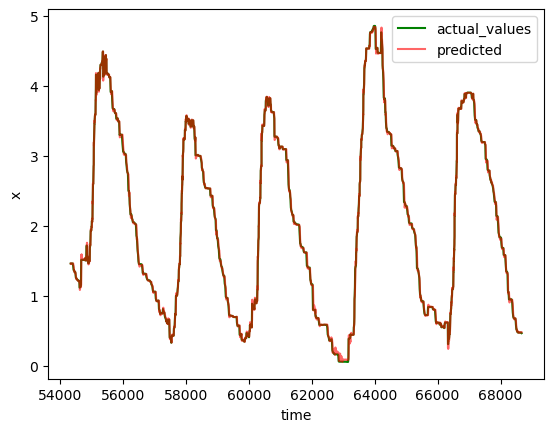

In [ ]:
train_size = int(len(brunswick_rain) * 0.8)
test_gddc = brunswick_gddc[train_size + 1:]

x_train = states[:train_size] 
y_train = brunswick_rain[1:train_size+1]

x_test = states[train_size: -1] 
y_test = brunswick_rain[train_size + 1:]

Vout = np.linalg.lstsq(x_train,y_train,rcond=None)[0]
#lstsq will return solution, residuals, rank, singular_vals

Y_predicted = np.matmul(x_test, Vout)

# plotting predictions for Brunswick Junction
plt.plot(test_gddc,y_test, label = 'actual_values',color='green',)
plt.plot(test_gddc,Y_predicted, label='predicted',color='red',alpha=0.6)
plt.xlabel('time')
plt.ylabel('x')
plt.legend()
plt.show()

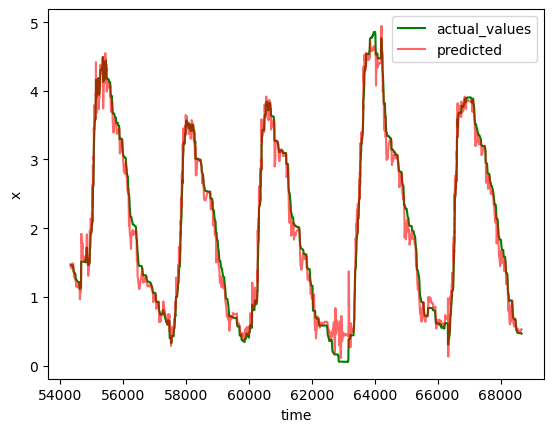

In [ ]:
# changing step size of prediction to 10 steps
Vout_10steps = np.linalg.lstsq(x_train[:-10],y_train[10:,],rcond=None)[0]
#lstsq will return solution, residuals, rank, singular_vals

Y_predicted = np.matmul(x_test, Vout_10steps)

plt.plot(test_gddc,y_test, label = 'actual_values',color='green',)
plt.plot(test_gddc,Y_predicted, label='predicted',color='red',alpha=0.6)
plt.xlabel('time')
plt.ylabel('x')
plt.legend()
plt.show()